# Experimento-base sem TV — só Dice, ScribblePrompt em 256²

**Objetivo:** isolar o efeito do **TV** sobre o experimento-base (`legado/base_dice_tv.ipynb`): tudo é igual, menos a perda, que aqui é só o soft Dice, sem nenhuma regularização do marcador. A hipótese do autor é que o TV, ao suavizar o marcador, junta os marcadores de núcleos vizinhos. A comparação é pareada por imagem com o `base_dice_tv` (mesmos *folds* e sementes) e com o Cellpose.

| Item | Valor |
|---|---|
| Perdas | soft Dice (sem TV, Size, DMap e Border) |
| Rede final | ScribblePrompt-UNet congelado, modo `positive` (canal positivo `relu(s − τ)/(1 − τ)`, τ = 0,5), entrada 256²; negativo zero |
| MarkerUNet | U-Net (smp), encoder ResNet34 ImageNet, entrada RGBA (alpha = máscara do Cellpose) |
| Treino | Adam lr 1e-4, batch 4, *grad clip* 1,0, *cosine schedule*, aumentação rot90 + flips sorteada a cada época |
| Protocolo | validação cruzada em 5 *folds* nas 37 imagens de treino (até 200 épocas, parada após 20 validações sem melhora do Dice); o modelo da melhor época de cada *fold* é gravado. **O teste não é usado aqui:** a configuração escolhida é avaliada uma única vez em `experimento_final.ipynb` |
| Linha de base | Cellpose sozinho, nas mesmas imagens |

**Saída:** `docs/estudo/resultados/base_dice/` (configuração e procedência, métricas por imagem da validação, curvas, resumo com a
comparação pareada com o Cellpose e figura com imagens da validação) e os modelos dos *folds* em
`MyDrive/cell-fuzzy-models/base_dice/` (no Colab). No Colab, a última célula baixa a pasta de resultados compactada.

Use um ambiente com **GPU**. Na GPU, o resultado pode variar um pouco entre execuções (operações não determinísticas do cuDNN).

## 0. Setup

In [1]:
import os
import subprocess
import sys

REPO_URL = "https://github.com/Pedro-io/cell-fuzzy-seg.git"
BRANCH = "homolog"


def find_repo_root(start="."):
    p = os.path.abspath(start)
    prev = None
    while p != prev:
        if os.path.isdir(os.path.join(p, "src")) and os.path.exists(os.path.join(p, "pyproject.toml")):
            return p
        prev, p = p, os.path.dirname(p)
    return None


if "google.colab" in sys.modules:
    repo_root = os.path.join("/content", "cell-fuzzy-seg")
    if os.path.exists(repo_root):
        subprocess.run(["git", "-C", repo_root, "fetch", "origin", BRANCH], check=True)
        subprocess.run(["git", "-C", repo_root, "checkout", BRANCH], check=True)
        subprocess.run(["git", "-C", repo_root, "pull", "--ff-only", "origin", BRANCH], check=True)
    else:
        subprocess.run(["git", "clone", "--branch", BRANCH, REPO_URL, repo_root], check=True)
else:
    repo_root = find_repo_root(os.getcwd())
    if repo_root is None:
        raise RuntimeError("Raiz do repositório não encontrada a partir do diretório atual.")

os.chdir(repo_root)
if repo_root not in sys.path:
    sys.path.insert(0, repo_root)
print("Repositório:", repo_root)
print(subprocess.run(["git", "log", "-1", "--oneline"], capture_output=True, text=True).stdout.strip())

Repositório: /content/cell-fuzzy-seg
2fc01fa fix(scribbleprompt): confere o SHA-256 do checkpoint no download


In [2]:
if "google.colab" in sys.modules:
    get_ipython().system("python -m pip install -r requirements.txt -q")
else:
    print("Ambiente local: verifique se as dependências do requirements.txt estão instaladas.")

  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.8/60.8 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 213.4/213.4 kB 12.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.8/40.8 MB 23.3 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.0/15.0 MB 107.9 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.6/61.6 kB 9.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 25.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.5/62.5 MB 16.2 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 20.5 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 808.6/808.6 kB 42.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 73.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 26.5/26.5 MB 79.0 MB/s eta 0:00:00:00:0100:01


## 1. Configuração

In [3]:
import json

import matplotlib.pyplot as plt
import numpy as np
import torch

from src.data.load.preprocessed_dataset import NEGATIVE_KEY, load_preprocessed
from src.evaluation.figures import pick_cases, prediction_figure
from src.evaluation.metrics import binary_metrics
from src.evaluation.report import save_run, summarize
from src.losses.loss_composer import LossComposer
from src.losses.terms import DiceTerm
from src.models.configs.marker_unet_config import UNET_CONFIG
from src.models.networks.final_segmentation.scribble_prompting_network import ScribblePromptingNetwork
from src.models.networks.marker_unet import MarkerUNet
from src.pipeline.steps.inference.frozen_segmentation_step import FrozenSegmentationStep
from src.pipeline.steps.inference.marker_step import MarkerStep
from src.pipeline.training_pipeline import TrainingPipeline
from src.training.checkpoints import fold_name, load_pipeline
from src.training.kfold import TrainConfig, final_epochs, run_kfold

EXPERIMENT_NAME = "base_dice"
OVERWRITE = False            # recusa gravar por cima de resultados ou modelos que já existem

RGBA_ALPHA = "mask"          # 4º canal da MarkerUNet: máscara do Cellpose ("prob": probabilidade)
SP_INPUT_SIZE = (256, 256)   # entrada do ScribblePrompt
TAU = 0.5                    # limiar do canal positivo
NEGATIVE_RADIUS = None           # None: sem negativo; n: negativo = pixels a mais de n px de qualquer máscara do Cellpose

CONFIG = TrainConfig(
    k=5, batch_size=4, max_epochs=200, patience=20, min_delta=0.0,
    lr=1e-4, grad_clip=1.0, threshold=0.5, seed=42, log_every=10,
)
DESCRIPTION = {
    "perdas": "soft Dice (1,0), sem regularização do marcador",
    "rede_final": f"ScribblePrompt-UNet v1 congelado, scribble_mode=positive, tau={TAU}, input_size={SP_INPUT_SIZE}"
                  + ("" if NEGATIVE_RADIUS is None
                     else f", negativo = fundo do Cellpose (faixa livre de {NEGATIVE_RADIUS} px)"),
    "marker_net": "MarkerUNet (smp Unet, resnet34 ImageNet, 4 canais)",
    "rgba_alpha": RGBA_ALPHA,
    "aumentacao": "rot90 + flips, sorteada a cada época",
}

assert torch.cuda.is_available() or "google.colab" not in sys.modules, "No Colab, use um ambiente com GPU."
print("Device:", CONFIG.device)
print(json.dumps(DESCRIPTION, indent=2, ensure_ascii=False))

Device: cuda
{
  "perdas": "soft Dice (1,0), sem regularização do marcador",
  "rede_final": "ScribblePrompt-UNet v1 congelado, scribble_mode=positive, tau=0.5, input_size=(256, 256)",
  "marker_net": "MarkerUNet (smp Unet, resnet34 ImageNet, 4 canais)",
  "rgba_alpha": "mask",
  "aumentacao": "rot90 + flips, sorteada a cada época"
}


## 2. Onde os modelos são gravados

In [8]:
# Modelos treinados: no Colab, no Google Drive de quem roda o notebook (sobrevive ao fim da sessão); fora dele,
# em ~/cell-fuzzy-models. Troque MODELS_ROOT para gravar em outro lugar.
if "google.colab" in sys.modules:
    try:
        from google.colab import drive

        drive.mount("/content/drive")
        MODELS_ROOT = "/content/drive/MyDrive/cell-fuzzy-models"
    except Exception as erro:
        print(f"Drive não montado ({erro}): os modelos ficam no disco da sessão e somem quando ela terminar.")
        MODELS_ROOT = "/content/cell-fuzzy-models"
else:
    MODELS_ROOT = os.path.expanduser(os.path.join("~", "cell-fuzzy-models"))
MODELS_DIR = os.path.join(MODELS_ROOT, EXPERIMENT_NAME)
print("Modelos em:", MODELS_DIR)

Mounted at /content/drive
Modelos em: /content/drive/MyDrive/cell-fuzzy-models/base_dice


## 3. Dados de treino e linha de base do Cellpose

In [9]:
train_samples = load_preprocessed("train", alpha=RGBA_ALPHA, negative_radius=NEGATIVE_RADIUS)
TRAIN_IDS = sorted(train_samples)
print(f"Treino: {len(train_samples)} imagens (o teste não é carregado neste notebook)")

d = [binary_metrics(s["cellpose_segmentation"] > 0, s["ground_truth"])["dice"] for s in train_samples.values()]
print(f"Cellpose sozinho, treino: Dice {np.mean(d):.4f} ± {np.std(d, ddof=1):.4f}")

Treino: 37 imagens (o teste não é carregado neste notebook)
Cellpose sozinho, treino: Dice 0.8450 ± 0.0302


## 4. Rede final (compartilhada) e montagem de cada experimento

In [10]:
checkpoint = ScribblePromptingNetwork.download_checkpoint(os.path.join(MODELS_ROOT, "scribbleprompt"))
FINAL_NET = ScribblePromptingNetwork(
    checkpoint=checkpoint, device=CONFIG.device, scribble_mode="positive",
    positive_threshold=TAU, input_size=SP_INPUT_SIZE,
)


def factory():
    """Monta um experimento novo: MarkerUNet recém-inicializada, pipeline e perdas.

    O ScribblePrompt é congelado e não guarda estado, então a mesma instância serve a todos os folds.
    """
    marker_net = MarkerUNet(config=UNET_CONFIG)
    pipeline = TrainingPipeline([
        MarkerStep(model=marker_net, differentiable=True, device=CONFIG.device),
        FrozenSegmentationStep(final_network=FINAL_NET, device=CONFIG.device,
                               negative_key=None if NEGATIVE_RADIUS is None else NEGATIVE_KEY),
    ])
    composer = LossComposer([DiceTerm()])
    return marker_net, pipeline, composer

16:12:00 | [ScribblePromptingNetwork] Baixando checkpoint de https://www.dropbox.com/scl/fi/pnw88n05irnv5z1snlklr/ScribblePrompt_unet_v1_nf192_res128.pt?rlkey=dr8xvkf0wj2r082h1zzpcmz5o&dl=1
16:12:02 | [ScribblePromptingNetwork] Checkpoint conferido e salvo em /content/drive/MyDrive/cell-fuzzy-models/scribbleprompt/ScribblePrompt_unet_v1_nf192_res128.pt


## 5. Validação cruzada

In [11]:
folds = run_kfold(factory, train_samples, TRAIN_IDS, CONFIG, models_dir=MODELS_DIR, overwrite=OVERWRITE)

for f in folds:
    cp = np.mean([r["cellpose_dice"] for r in f.rows])
    print(f"fold {f.fold}: melhor época {f.best_epoch:3d} de {f.epochs_run:3d} | Dice val {f.best_dice:.4f} | Cellpose {cp:.4f}")

16:12:02 | [kfold] fold 1/5: 29 treino, 8 validação
16:12:48 | [TrainingLoop] Epoch 10/200 | train_loss=0.3381 | val_loss=0.3798 | val_dice=0.5835 | best_dice=0.6115 | best_epoch=8
16:13:33 | [TrainingLoop] Epoch 20/200 | train_loss=0.2619 | val_loss=0.2893 | val_dice=0.6608 | best_dice=0.7053 | best_epoch=16
16:14:20 | [TrainingLoop] Epoch 30/200 | train_loss=0.2183 | val_loss=0.2390 | val_dice=0.7158 | best_dice=0.7158 | best_epoch=30
16:15:06 | [TrainingLoop] Epoch 40/200 | train_loss=0.2228 | val_loss=0.2475 | val_dice=0.7109 | best_dice=0.7307 | best_epoch=37
16:15:54 | [TrainingLoop] Epoch 50/200 | train_loss=0.1964 | val_loss=0.2397 | val_dice=0.7176 | best_dice=0.7307 | best_epoch=37
16:16:41 | [TrainingLoop] Epoch 60/200 | train_loss=0.1932 | val_loss=0.2262 | val_dice=0.7339 | best_dice=0.7404 | best_epoch=58
16:17:26 | [TrainingLoop] Epoch 70/200 | train_loss=0.1896 | val_loss=0.2327 | val_dice=0.7233 | best_dice=0.7405 | best_epoch=63
16:18:12 | [TrainingLoop] Epoch 80/200 

fold 0: melhor época  63 de  83 | Dice val 0.7405 | Cellpose 0.8363
fold 1: melhor época 122 de 142 | Dice val 0.7981 | Cellpose 0.8442
fold 2: melhor época 137 de 157 | Dice val 0.7939 | Cellpose 0.8586
fold 3: melhor época 136 de 156 | Dice val 0.7951 | Cellpose 0.8437
fold 4: melhor época 135 de 155 | Dice val 0.8035 | Cellpose 0.8438


## 6. Registro e resumo

In [12]:
N_EPOCHS = final_epochs(folds)
run_dir = save_run(EXPERIMENT_NAME, CONFIG, folds, final_epochs=N_EPOCHS, description=DESCRIPTION, overwrite=OVERWRITE)
print("Resultados em:", run_dir)
print("Épocas do treino final, se esta configuração for a escolhida (mediana das melhores épocas):", N_EPOCHS)

linhas = [r for f in folds for r in f.rows]
d = summarize(linhas)["dice"]
print(f"validação ({CONFIG.k} folds, {len(linhas)} imagens): Dice {d['mean']:.4f} ± {d['std']:.4f} "
      f"(IC95 {d['ci95'][0]:.4f}–{d['ci95'][1]:.4f}) | Cellpose {d['baseline_mean']:.4f} | "
      f"Δ {d['diff_mean']:+.4f} (IC95 {d['diff_ci95'][0]:+.4f}–{d['diff_ci95'][1]:+.4f}) | "
      f"melhora/piora {d['n_better']}/{d['n_worse']} | Wilcoxon p {d['wilcoxon_p']:.3g}")
print(f"marcador: média {np.mean([r['marker_mean_nucleo'] for r in linhas]):.3f} dentro dos núcleos do GT e "
      f"{np.mean([r['marker_mean_fundo'] for r in linhas]):.3f} fora")

Resultados em: docs/estudo/resultados/base_dice
Épocas do treino final, se esta configuração for a escolhida (mediana das melhores épocas): 135
validação (5 folds, 37 imagens): Dice 0.7853 ± 0.0503 (IC95 0.7689–0.8006) | Cellpose 0.8450 | Δ -0.0597 (IC95 -0.0724–-0.0489) | melhora/piora 0/37 | Wilcoxon p 1.46e-11
marcador: média 0.480 dentro dos núcleos do GT e 0.284 fora


### Como ler o resumo acima

- **`Resultados em`:** a pasta onde ficaram as métricas por imagem, as curvas, a configuração e a figura.
- **`Épocas do treino final`:** a mediana das melhores épocas dos 5 *folds*. Só é usada se esta configuração for a escolhida: o
  `experimento_final.ipynb` treina por esse número de épocas.
- **Linha `validação`** — cada uma das 37 imagens de treino foi prevista pelo modelo do *fold* em que ela ficou de fora, então
  nenhuma nota vem de uma imagem vista no treino:
  - **`Dice média ± desvio`:** o Dice médio das 37 imagens e o desvio padrão entre elas (quanto o resultado varia de imagem para
    imagem). Dice vai de 0 (nada em comum com o ground truth) a 1 (igual ao ground truth).
  - **`IC95`:** intervalo de confiança de 95% da média, por *bootstrap* (reamostragem das imagens): a faixa em que a média
    provavelmente estaria com outras imagens parecidas.
  - **`Cellpose`:** o Dice médio do Cellpose sozinho nas mesmas 37 imagens (a linha de base que o pipeline precisa superar).
  - **`Δ`:** a diferença média, imagem por imagem, entre o pipeline e o Cellpose (negativa = o pipeline perde), com o IC95 dela.
    Se o intervalo não cruza o zero, a diferença é consistente.
  - **`melhora/piora`:** em quantas imagens o pipeline ganhou e em quantas perdeu do Cellpose.
  - **`Wilcoxon p`:** teste pareado (as mesmas imagens nos dois métodos). Abaixo de 0,05, a diferença dificilmente é acaso.
- **Linha `marcador`:** o valor médio do marcador da MarkerUNet **dentro** dos núcleos do ground truth e **fora** deles. Se os dois
  forem parecidos, o marcador não distingue núcleo de fundo (por exemplo, um campo quase uniforme); quanto maior a diferença, mais
  o marcador "aponta" para os núcleos.

## 7. Imagens da validação: marcadores e segmentação

Três imagens da validação (a de pior, a mediana e a de melhor diferença de Dice em relação ao Cellpose), cada uma prevista pelo
modelo do *fold* em que ficou de fora, carregado da pasta dos modelos. Painéis: imagem, ground truth, máscara do Cellpose,
marcador (na escala 0–1 e com o contraste esticado), canal positivo que chega ao ScribblePrompt e segmentação. Recorte central de
400 px. A figura é salva na pasta do experimento.

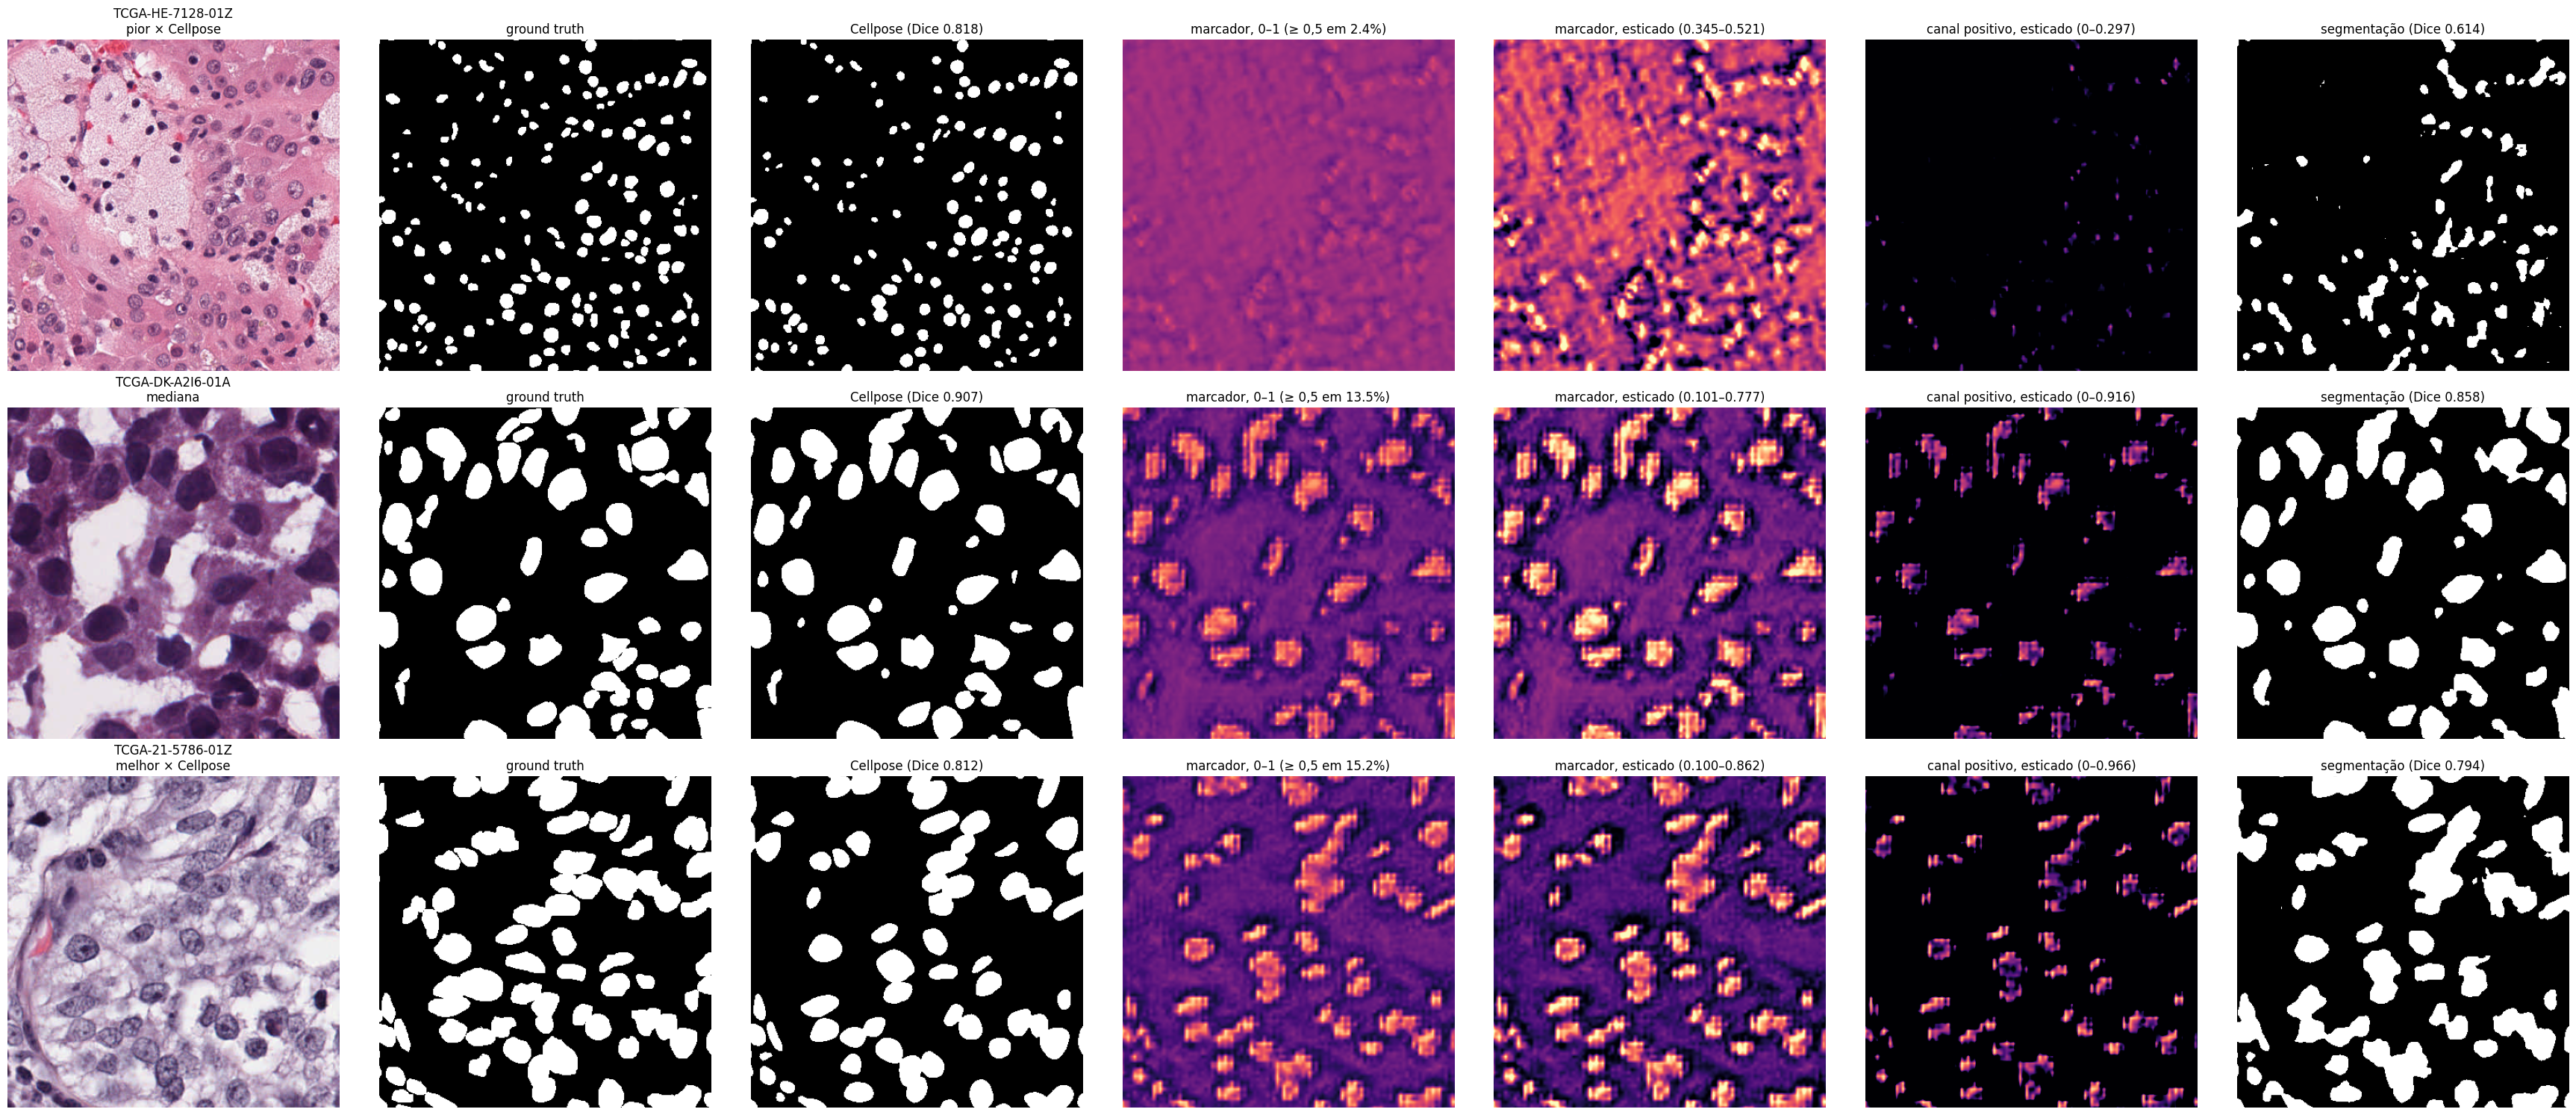

In [13]:
casos = [(rotulo, r, load_pipeline(factory, MODELS_DIR, fold_name(r["fold"]))[0])
         for rotulo, r in pick_cases(linhas)]
fig = prediction_figure(casos, train_samples, crop=400, threshold=CONFIG.threshold, device=CONFIG.device)
fig.savefig(os.path.join(run_dir, "figura_validacao.png"), dpi=80, bbox_inches="tight")
plt.show()

### Como ler a figura acima

Cada **linha** é uma imagem: imagens da **validação**, cada uma prevista pelo modelo do *fold* em que ela ficou de fora (carregado do Drive). As três foram escolhidas pela diferença de Dice contra o Cellpose: a **pior** (onde o
pipeline mais perde), a **mediana** e a **melhor** (onde mais ganha ou menos perde). O rótulo e o nome da imagem estão à esquerda.
Todos os painéis mostram o mesmo recorte central de 400 × 400 px da imagem de 1000 × 1000; os Dice dos títulos são da imagem
inteira.

| Coluna | O que mostra | Como ler |
|---|---|---|
| 1. imagem | a imagem H&E original | os núcleos são as manchas roxas escuras |
| 2. ground truth | a anotação manual: branco = núcleo, preto = fundo | é a resposta certa |
| 3. Cellpose | a segmentação do Cellpose sozinho (branco = núcleo) e o Dice dela | é a linha de base a superar |
| 4. marcador, 0–1 | a saída da MarkerUNet, na escala fixa de 0 (escuro) a 1 (claro); o título dá a fração da imagem com marcador ≥ 0,5 | mostra o nível do marcador; se tudo parecer da mesma cor, ele está quase constante (por exemplo, tudo perto de 0,5) |
| 5. marcador, esticado | o mesmo marcador com as cores esticadas entre os percentis 1 e 99 do recorte (o intervalo está no título) | revela a forma do marcador mesmo quando os valores são parecidos; um bom marcador fica claro sobre os núcleos da coluna 2 e escuro no fundo |
| 6. canal positivo, esticado | o que de fato entra no ScribblePrompt como "aqui há núcleo": `relu(m − 0,5)/0,5`, zero onde o marcador é menor que 0,5; cores esticadas de 0 ao máximo (no título) | um máximo baixo no título significa um positivo fraco; as partes pretas não indicam nada à rede |
| 7. segmentação | a saída final do ScribblePrompt, binarizada no limiar 0,5 (branco = núcleo), e o Dice dela | compare com a coluna 2 (o certo) e com a 3 (o Cellpose): núcleos inchados ou colados indicam excesso; núcleos faltando, falta |

O canal negativo, quando o experimento usa o do Cellpose, não aparece: ele é fixo (1 nos pixels a mais de alguns pixels de
qualquer máscara do Cellpose) e não depende do treino.

## 8. Curvas e comparação por imagem

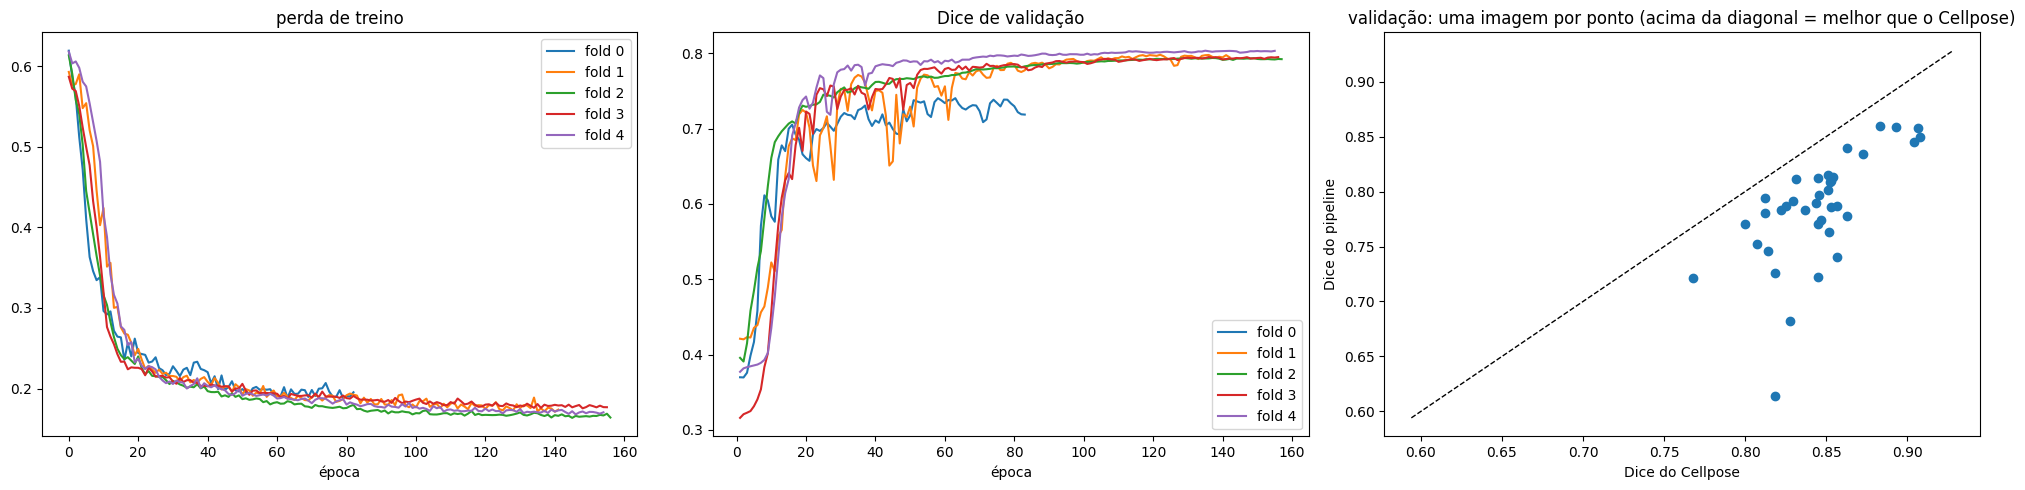

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for f in folds:
    axes[0].plot(f.train_loss_history, label=f"fold {f.fold}")
    axes[1].plot([h["epoch"] for h in f.val_dice_history], [h["dice"] for h in f.val_dice_history], label=f"fold {f.fold}")
axes[0].set_title("perda de treino")
axes[1].set_title("Dice de validação")
for ax in axes[:2]:
    ax.set_xlabel("época")
    ax.legend()

dice = np.array([r["dice"] for r in linhas])
base = np.array([r["cellpose_dice"] for r in linhas])
axes[2].scatter(base, dice)
lo, hi = min(dice.min(), base.min()) - 0.02, max(dice.max(), base.max()) + 0.02
axes[2].plot([lo, hi], [lo, hi], "k--", lw=1)
axes[2].set_xlabel("Dice do Cellpose")
axes[2].set_ylabel("Dice do pipeline")
axes[2].set_title("validação: uma imagem por ponto (acima da diagonal = melhor que o Cellpose)")
plt.tight_layout()
plt.show()

### Como ler os gráficos acima

- **Perda de treino** (esquerda): uma curva por *fold*, época a época. Ela deve cair e se estabilizar; o fim de cada curva é a
  época em que o treino daquele *fold* parou (20 validações seguidas sem melhora do Dice).
- **Dice de validação** (centro): o Dice médio das imagens que ficaram de fora em cada *fold*, época a época. O modelo guardado de
  cada *fold* é o da época do pico dessa curva, não o da última época.
- **Uma imagem por ponto** (direita): no eixo horizontal, o Dice do Cellpose; no vertical, o do pipeline, na mesma imagem. Pontos
  **acima da diagonal** tracejada são imagens em que o pipeline ganhou do Cellpose; **abaixo**, imagens em que perdeu. Quanto mais
  longe da diagonal, maior a diferença.

## 9. Baixar os resultados (Colab)

In [15]:
if "google.colab" in sys.modules:
    import shutil

    from google.colab import files

    archive = shutil.make_archive(f"/content/{EXPERIMENT_NAME}", "zip", root_dir=os.path.dirname(run_dir),
                                  base_dir=EXPERIMENT_NAME)
    files.download(archive)  # descompactar em docs/estudo/resultados/

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>